In [5]:
%pip install matplotlib

                                              0.0/8.2 MB ? eta -:--:--
     -                                        0.3/8.2 MB 10.2 MB/s eta 0:00:01
     -----                                    1.1/8.2 MB 13.4 MB/s eta 0:00:01
     ---------                                1.9/8.2 MB 15.3 MB/s eta 0:00:01
     ------------                             2.5/8.2 MB 14.7 MB/s eta 0:00:01
     ---------------                          3.2/8.2 MB 14.6 MB/s eta 0:00:01
     ------------------                       3.8/8.2 MB 14.4 MB/s eta 0:00:01
     ---------------------                    4.5/8.2 MB 14.3 MB/s eta 0:00:01
     ------------------------                 5.1/8.2 MB 14.2 MB/s eta 0:00:01
     ---------------------------              5.7/8.2 MB 14.1 MB/s eta 0:00:01
     -------------------------------          6.4/8.2 MB 14.0 MB/s eta 0:00:01
     ----------------------------------       7.0/8.2 MB 14.0 MB/s eta 0:00:01
     -------------------------------------    7.6/8.2 MB 13.


[notice] A new release of pip is available: 23.1.2 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
from scipy.linalg import cholesky, solve_triangular, svd

def random_nystrom(A, k, l, rng):
    n = A.shape[0]
    Omega = rng.standard_normal((n, l))
    Y = A @ Omega
    nu = np.sqrt(n) * np.spacing(np.linalg.norm(Y, 2))
    Y_nu = Y + nu * Omega
    C = cholesky(Omega.T @ Y_nu, lower=False)
    B = solve_triangular(C.T, Y_nu.T, lower=True).T
    U, sigma, V = svd(B, full_matrices=False)
    lam_all = np.maximum(0.0, sigma**2 - nu)
    U1 = U[:, :k]
    lam = lam_all[:k]
    Ahat = U1 @ np.diag(lam) @ U1.T
    return U1, lam, Ahat

In [3]:
rng = np.random.default_rng(0)
n = 200
r = 100
X = rng.standard_normal((n, r))
A = X @ X.T
k = 50
l = 100
U, lam, Ahat = random_nystrom(A, k, l, rng)
err_2 = np.linalg.norm(A - Ahat, ord="fro")
rank_Ahat = np.linalg.matrix_rank(Ahat)

print("Approximate rank:", rank_Ahat)
print("Frobenius error:", err_2)

Approximate rank: 50
Frobenius error: 662.6722186782222



kernel = linear
full krr mse = 1.569913704976865
full krr runtime = 0.32243679999373853

l = 10
uniform mse = 1.5699137050162417
uniform forward error = 1.921143756050666e-14
uniform runtime = 0.22747120005078614
gaussian mse = 1.5699136765154935
gaussian forward error = 5.675035805325746e-10
gaussian runtime = 0.2533205999061465

l = 50
uniform mse = 1.5699137049973892
uniform forward error = 8.381849322169493e-16
uniform runtime = 0.3178252000361681
gaussian mse = 1.569913709222426
gaussian forward error = 7.009789668796582e-13
gaussian runtime = 0.3460762999020517

l = 100
uniform mse = 1.5699137049887504
uniform forward error = 1.0128517566946755e-15
uniform runtime = 0.2096824999898672
gaussian mse = 1.5699137036001278
gaussian forward error = 6.049024055653205e-13
gaussian runtime = 0.19972020015120506

l = 200
uniform mse = 1.5699137049665655
uniform forward error = 7.956281597963316e-16
uniform runtime = 0.2636824999935925
gaussian mse = 1.5699137002027448
gaussian forward err

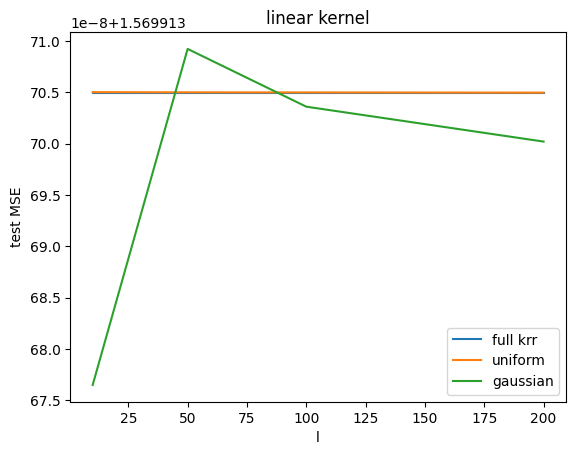

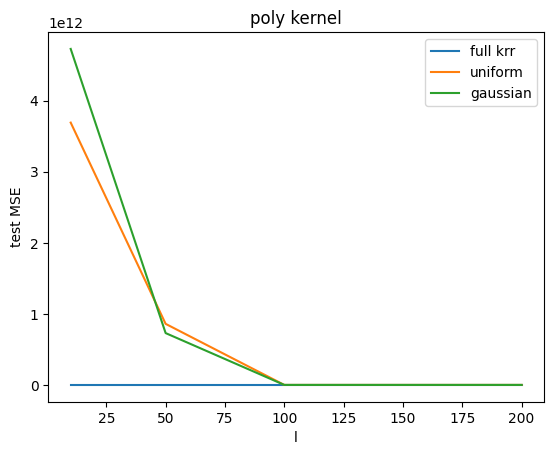

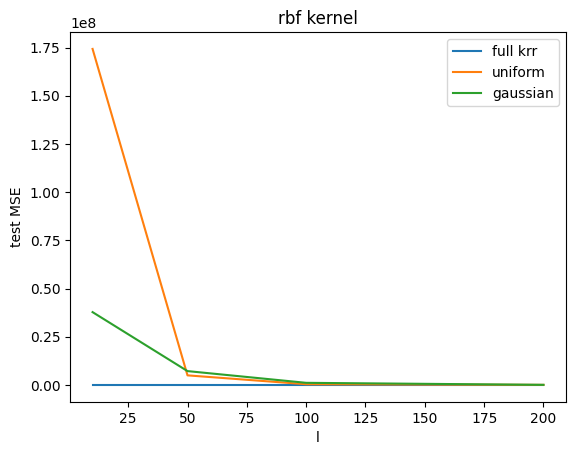

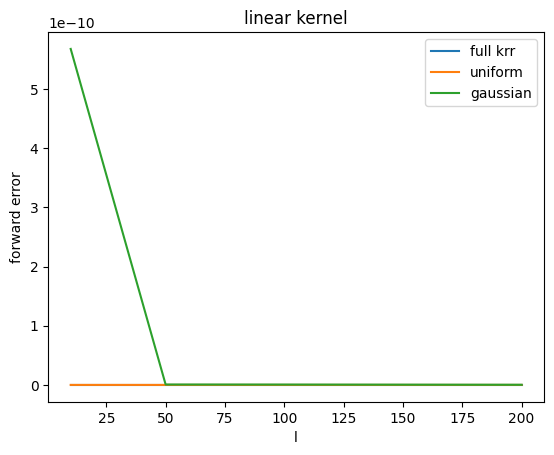

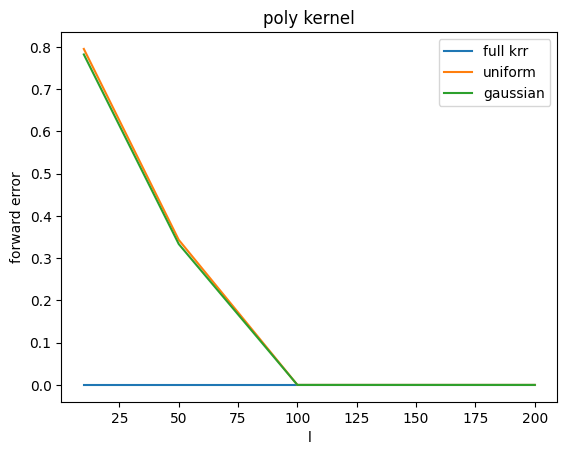

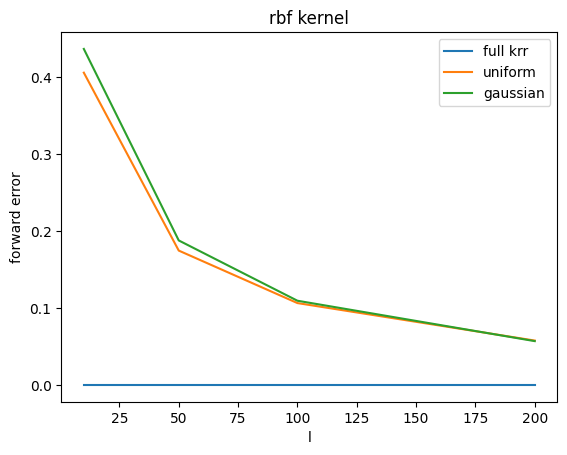

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.linalg import cholesky, solve_triangular, svd

def random_nystrom(A, k, l, rng):
    n = A.shape[0]
    Omega = rng.standard_normal((n, l))
    Y = A @ Omega
    nu = np.sqrt(n) * np.spacing(np.linalg.norm(Y, 2))
    Y_nu = Y + nu * Omega
    C = cholesky(Omega.T @ Y_nu, lower=False)
    B = solve_triangular(C.T, Y_nu.T, lower=True).T
    U, sigma, V = svd(B, full_matrices=False)
    lam_all = np.maximum(0.0, sigma**2 - nu)
    U1 = U[:, :k]
    lam = lam_all[:k]
    Ahat = U1 @ np.diag(lam) @ U1.T
    return U1, lam, Ahat

rng = np.random.default_rng(0)

n = 1000
d = 10
X = rng.standard_normal((n,d))
y_true = X[:,0]*X[:,1] + np.exp(-X[:,2]**2) + np.sin(X[:,3])
noise = 1e-3*rng.standard_normal(n)
y = y_true + noise

ind = rng.permutation(n)

n_train = 800
train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train = X[train_ind]
y_train = y[train_ind]
X_test = X[test_ind]
y_test = y[test_ind]

def linear(X,Z):
    K = X @ Z.T
    return K

def poly(X,Z):
    K = (X @ Z.T + 1.0)**2
    return K

def rbf(X,Z):
    gamma = 0.1
    X_norm = np.sum(X**2,axis=1)
    Z_norm = np.sum(Z**2,axis=1)
    dist = X_norm[:,None] + Z_norm[None,:] - 2*X@Z.T
    K = np.exp(-gamma*dist)
    return K

def get_error(y_test,y_hat): #mse
    err = np.mean((y_test-y_hat)**2)
    return err


kernel_names = ["linear","poly","rbf"]
kernel_list = [linear,poly,rbf]
l_values = [10,50,100,200]
results = []

for a in range(len(kernel_list)):
    lam = 1e-3
    name = kernel_names[a]
    kernel = kernel_list[a]
    print("")
    print("kernel =",name)

    t0 = time.perf_counter()

    K_train = kernel(X_train,X_train)
    K_test = kernel(X_test,X_train)
    alpha = np.linalg.solve(K_train + lam*np.eye(n_train),y_train) #full krr
    y_hat = K_test @ alpha
    full_time = time.perf_counter() - t0
    full_mse = get_error(y_test,y_hat)

    print("full krr mse =",full_mse)
    print("full krr runtime =",full_time)

    for l in l_values:
        print("")
        print("l =",l)

        t0 = time.perf_counter()

        sample_ind = rng.choice(n_train,size=l,replace=False) #random uniform
        C = K_train[:,sample_ind]
        W = K_train[sample_ind, :]
        W = W[:, sample_ind]
        K_uni = C @ np.linalg.pinv(W) @ C.T
        alpha_uni = np.linalg.solve(K_uni + lam*np.eye(n_train),y_train)
        y_hat_uni = K_test @ alpha_uni

        uni_time = time.perf_counter() - t0

        uni_mse = get_error(y_test,y_hat_uni)
        uni_fro = np.linalg.norm(K_train-K_uni,ord="fro")/np.linalg.norm(K_train,ord="fro")

        print("uniform mse =",uni_mse)
        print("uniform forward error =",uni_fro)
        print("uniform runtime =",uni_time)

        t0 = time.perf_counter()

        U, eigs, K_gauss = random_nystrom(K_train,l,l,rng) #gaussian method
        alpha_gauss = np.linalg.solve(K_gauss + lam*np.eye(n_train),y_train)
        y_hat_gauss = K_test @ alpha_gauss

        gauss_time = time.perf_counter() - t0

        gauss_mse = get_error(y_test,y_hat_gauss)
        gauss_fro = np.linalg.norm(K_train-K_gauss,ord="fro")/np.linalg.norm(K_train,ord="fro")

        print("gaussian mse =",gauss_mse)
        print("gaussian forward error =",gauss_fro)
        print("gaussian runtime =",gauss_time)

        results.append([name,l,"full",full_mse,0.0,full_time])
        results.append([name,l,"uniform",uni_mse,uni_fro,uni_time])
        results.append([name,l,"gaussian",gauss_mse,gauss_fro,gauss_time])

print("")
print("results")
print("kernel, l, method, mse, forward error, time")
for row in results:
    print(row)

for name in kernel_names:
    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[3])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[3])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[3])

    plt.figure()
    plt.plot(l_plot,full_plot,label="full krr")
    plt.plot(l_plot,uni_plot,label="uniform")
    plt.plot(l_plot,gauss_plot,label="gaussian")
    plt.xlabel("l")
    plt.ylabel("test MSE")
    plt.title(name + " kernel")
    plt.legend()
    plt.show()

for name in kernel_names:

    l_plot = []
    full_plot = []
    uni_plot = []
    gauss_plot = []

    for row in results:
        if row[0] == name and row[2] == "full":
            l_plot.append(row[1])
            full_plot.append(row[4])
        if row[0] == name and row[2] == "uniform":
            #l_plot.append(row[1])
            uni_plot.append(row[4])
        if row[0] == name and row[2] == "gaussian":
            gauss_plot.append(row[4])

    plt.figure()
    plt.plot(l_plot,full_plot,label="full krr")
    plt.plot(l_plot,uni_plot,label="uniform")
    plt.plot(l_plot,gauss_plot,label="gaussian")
    plt.xlabel("l")
    plt.ylabel("forward error")
    plt.title(name + " kernel")
    plt.legend()
    plt.show()


l = 10
uniform forward error = 0.9000639504751639
gaussian forward error = 0.9091644828516653

l = 50
uniform forward error = 0.5804791694058935
gaussian forward error = 0.5789155471296293

l = 100
uniform forward error = 0.28761519159093063
gaussian forward error = 0.30037794062004

l = 200
uniform forward error = 0.05952993135664101
gaussian forward error = 0.057719066613576384

l = 400
uniform forward error = 0.0012239243058334273
gaussian forward error = 0.0012716876654798516


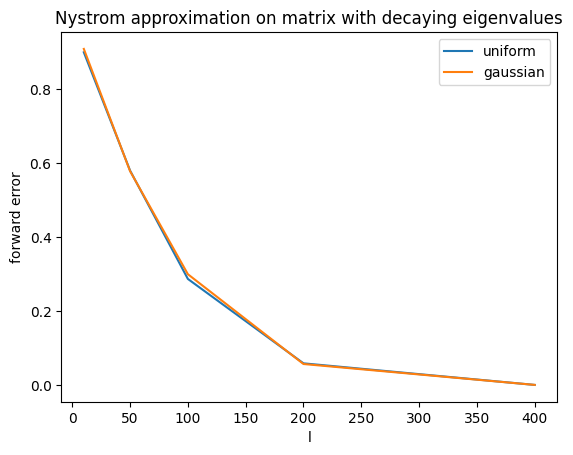

In [7]:
rng = np.random.default_rng(1)
n = 1000
Q, R = np.linalg.qr(rng.standard_normal((n,n)))
eigs = np.logspace(0,-10,n)
A = Q @ np.diag(eigs) @ Q.T

l_values = [10,50,100,200,400]
l_plot = []
uni_plot = []
gauss_plot = []

for l in l_values:

    sample_ind = rng.choice(n,size=l,replace=False)
    C = A[:,sample_ind]
    W = A[sample_ind, :]
    W = W[:, sample_ind]
    A_uni = C @ np.linalg.pinv(W) @ C.T
    U, lam_gauss, A_gauss = random_nystrom(A,l,l,rng)

    uni_err = np.linalg.norm(A-A_uni,ord="fro")/np.linalg.norm(A,ord="fro")
    gauss_err = np.linalg.norm(A-A_gauss,ord="fro")/np.linalg.norm(A,ord="fro")

    print("")
    print("l =",l)
    print("uniform forward error =",uni_err)
    print("gaussian forward error =",gauss_err)

    l_plot.append(l)
    uni_plot.append(uni_err)
    gauss_plot.append(gauss_err)

plt.figure()
plt.plot(l_plot,uni_plot,label="uniform")
plt.plot(l_plot,gauss_plot,label="gaussian")
plt.xlabel("l")
plt.ylabel("forward error")
plt.title("Nystrom approximation on matrix with decaying eigenvalues")
plt.legend()
plt.show()